<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS07/JS07_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Klasterisasi
## Tugas Lab - Klasterisasi Data Nasabah Kartu Kredit

**Soal**
1. Buat *scatter plot* dengan dua variabel `Avg_Credit_Limit` dan `Total_credit_card`. Apakah sebaran data dapat dikatakan linier?
2. Buat model K-Means. Tentukan $k$ terbaik dengan *elbow method* (lengkapi *line chart* dan analisis).
3. Gambarkan hasil klasterisasi K-Means dengan *scatter plot*.
4. Buat model DBSCAN **dengan seluruh variabel yang dapat digunakan**.
5. Tentukan parameter terbaik dengan *elbow method* (*line chart* + analisis).
6. Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

## Persiapan - Import Library dan Load Dataset

Unduh dataset dari modul (data nasabah kartu kredit, biasanya bernama `Credit Card Customer Data.csv`), lalu letakkan satu folder dengan notebook ini atau upload ke Google Colab. Sel berikut mencari file `.csv` yang memiliki kolom `Avg_Credit_Limit`; jika tidak ada dan Anda memakai Colab, dialog upload akan muncul.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_style('whitegrid')


def cari_csv():
    for f in glob.glob('*.csv'):
        try:
            if 'Avg_Credit_Limit' in pd.read_csv(f, nrows=1).columns:
                return f
        except Exception:
            pass
    return None


path = cari_csv()
if path is None:
    try:
        from google.colab import files
        print('Silakan upload file dataset kartu kredit (.csv)')
        files.upload()
        path = cari_csv()
    except ImportError:
        pass

if path is None:
    raise FileNotFoundError('Dataset tidak ditemukan. Letakkan file .csv (kolom Avg_Credit_Limit) di folder yang sama dengan notebook ini.')

df = pd.read_csv(path)
print('File dataset :', path)
print('Ukuran data  :', df.shape)
df.head()

Silakan upload file dataset kartu kredit (.csv)


Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv
File dataset : CC_Customer_Dataset.csv
Ukuran data  : (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [3]:
print('Missing values per kolom:')
print(df.isna().sum())
print()
print('Baris duplikat:', df.duplicated().sum())
df.describe().T

Missing values per kolom:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Baris duplikat: 0


,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.500000,190.669872,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.443939,25627.772200,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.00,3.0,5.00,10.0


Kolom `Sl_No` dan `Customer Key` adalah **identitas** nasabah (bukan ciri/perilaku), sehingga tidak dipakai sebagai fitur klasterisasi. Nama kolom jumlah kartu pada soal ditulis `Total_credit_card`; di bawah ini nama kolom sebenarnya dideteksi otomatis agar tidak salah ketik.

In [4]:
# Deteksi nama kolom sebenarnya (huruf besar/kecil bisa berbeda dari soal)
col_limit = next(c for c in df.columns if c.lower() == 'avg_credit_limit')
col_cards = next(c for c in df.columns if c.lower().startswith('total_credit_card'))

# Kolom identitas yang tidak dipakai
kolom_id = [c for c in df.columns if c.lower() in ('sl_no', 'customer key', 'customer_key')]

# Seluruh variabel yang dapat digunakan = semua kolom numerik selain identitas
fitur_semua = [c for c in df.select_dtypes(include='number').columns if c not in kolom_id]

print('Kolom limit kredit  :', col_limit)
print('Kolom jumlah kartu  :', col_cards)
print('Kolom identitas     :', kolom_id)
print('Fitur untuk DBSCAN  :', fitur_semua)

Kolom limit kredit  : Avg_Credit_Limit
Kolom jumlah kartu  : Total_Credit_Cards
Kolom identitas     : ['Sl_No', 'Customer Key']
Fitur untuk DBSCAN  : ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


## Soal 1 - Scatter Plot `Avg_Credit_Limit` vs `Total_credit_card`

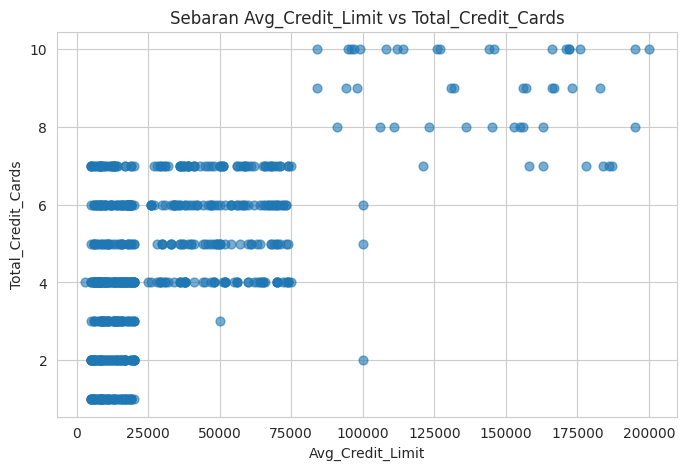

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df[col_limit], df[col_cards], s=40, alpha=0.6)
plt.xlabel(col_limit)
plt.ylabel(col_cards)
plt.title(f'Sebaran {col_limit} vs {col_cards}')
plt.show()

Korelasi Pearson  (linear)    : 0.6089
Korelasi Spearman (monotonik) : 0.5175
R^2 garis linear              : 0.3707


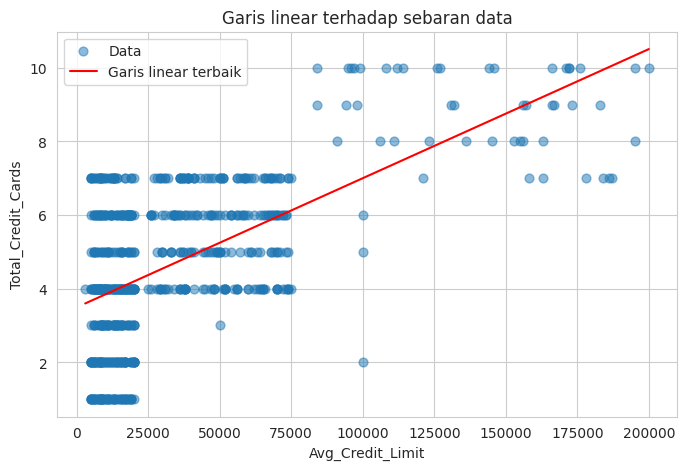

In [6]:
# Bukti kuantitatif untuk menilai kelinieran
r = df[col_limit].corr(df[col_cards])               # Pearson (hubungan linear)
rho = df[col_limit].corr(df[col_cards], method='spearman')  # Spearman (hubungan monotonik)
print(f'Korelasi Pearson  (linear)    : {r:.4f}')
print(f'Korelasi Spearman (monotonik) : {rho:.4f}')

# Regresi linear sederhana untuk melihat seberapa baik garis lurus menjelaskan data
b, a = np.polyfit(df[col_limit], df[col_cards], 1)
pred = a + b * df[col_limit]
ss_res = ((df[col_cards] - pred) ** 2).sum()
ss_tot = ((df[col_cards] - df[col_cards].mean()) ** 2).sum()
print(f'R^2 garis linear              : {1 - ss_res / ss_tot:.4f}')

plt.figure(figsize=(8, 5))
plt.scatter(df[col_limit], df[col_cards], s=40, alpha=0.5, label='Data')
xs = np.linspace(df[col_limit].min(), df[col_limit].max(), 100)
plt.plot(xs, a + b * xs, 'r-', label='Garis linear terbaik')
plt.xlabel(col_limit); plt.ylabel(col_cards); plt.legend()
plt.title('Garis linear terhadap sebaran data')
plt.show()

### Analisis Soal 1

Sebaran data **tidak dapat dikatakan linier**. Alasannya:
- Titik-titik tidak membentuk pola garis lurus: hanya terdapat beberapa nilai jumlah kartu yang diskrit (bukan kontinu), dan pada tiap nilai tersebut `Avg_Credit_Limit` menyebar pada rentang yang sangat lebar dan saling tumpang tindih.
- Garis linear terbaik hanya menjelaskan sebagian kecil variasi data (lihat nilai $R^2$ di atas), dan koefisien korelasi (Pearson/Spearman) tidak mendekati ±1.
- Secara visual terlihat kelompok-kelompok yang berbeda (misalnya nasabah dengan limit sangat tinggi tapi jumlah kartu banyak), bukan satu hubungan linear tunggal.

Artinya kelompok nasabah muncul dari **gabungan** kedua variabel, bukan dari hubungan linear antara keduanya. Inilah alasan klasterisasi relevan di sini.

## Soal 2 - K-Means dan Penentuan $k$ dengan Elbow Method

**Catatan skala data:** `Avg_Credit_Limit` berada pada rentang puluhan ribu, sedangkan `Total_credit_card` hanya 1-10. K-Means memakai jarak Euclidean sehingga tanpa penskalaan, hasil klasterisasi akan **didominasi hampir sepenuhnya oleh `Avg_Credit_Limit`**. Karena itu fitur dinormalisasi dengan `StandardScaler` sebelum dilatih. Hasil *cluster* tetap digambarkan pada sumbu asli (tidak terskala) agar mudah dibaca.

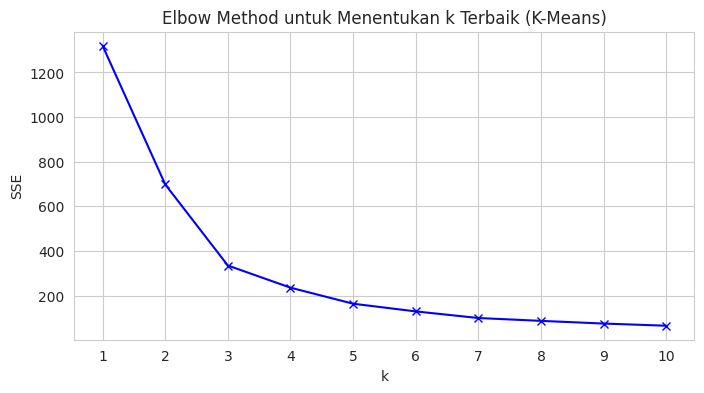

In [7]:
fitur_kmeans = [col_limit, col_cards]
X_km_raw = df[fitur_kmeans].values
scaler_km = StandardScaler()
X_km = scaler_km.fit_transform(X_km_raw)

# Elbow method: SSE (inertia) untuk k = 1..10
K = range(1, 11)
sse = []
for k in K:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_km)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method untuk Menentukan k Terbaik (K-Means)')
plt.xticks(list(K))
plt.show()

In [8]:
def titik_siku(x, y):
    """Titik 'siku' = titik kurva dengan jarak terjauh dari garis lurus
    yang menghubungkan titik pertama dan terakhir (metode jarak ke garis)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = xn[0], yn[0], xn[-1], yn[-1]
    # jarak tegak lurus setiap titik ke garis (x1,y1)-(x2,y2)
    d = np.abs((y2 - y1) * xn - (x2 - x1) * yn + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(np.argmax(d)), d


idx, _ = titik_siku(list(K), sse)
k_terbaik = list(K)[idx]

print('k | SSE | penurunan dari k sebelumnya | % penurunan')
for i, (k, s) in enumerate(zip(K, sse)):
    if i == 0:
        print(f'{k} | {s:10.2f} | - | -')
    else:
        turun = sse[i - 1] - s
        print(f'{k} | {s:10.2f} | {turun:10.2f} | {100 * turun / sse[i - 1]:5.1f}%')

print(f'\nk terbaik berdasarkan titik siku (elbow): {k_terbaik}')

k | SSE | penurunan dari k sebelumnya | % penurunan
1 |    1320.00 | - | -
2 |     698.29 |     621.71 |  47.1%
3 |     334.72 |     363.57 |  52.1%
4 |     235.39 |      99.33 |  29.7%
5 |     163.47 |      71.92 |  30.6%
6 |     128.96 |      34.51 |  21.1%
7 |      99.37 |      29.59 |  22.9%
8 |      86.53 |      12.84 |  12.9%
9 |      74.53 |      12.00 |  13.9%
10 |      64.83 |       9.70 |  13.0%

k terbaik berdasarkan titik siku (elbow): 3


k | silhouette
2 | 0.6484
3 | 0.4901
4 | 0.4569
5 | 0.5023
6 | 0.5141
7 | 0.5184
8 | 0.4832
9 | 0.4973
10 | 0.5057


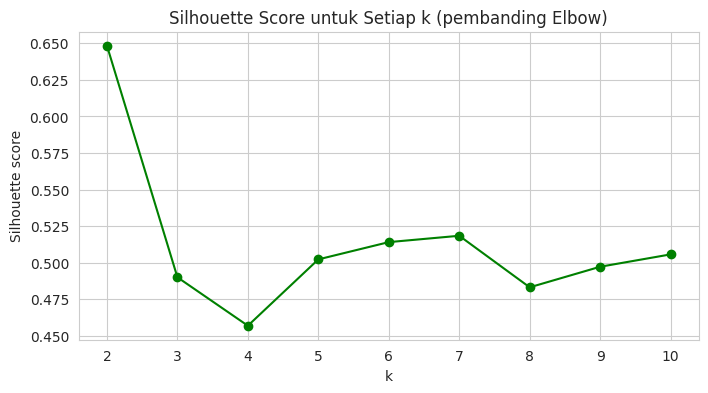

In [9]:
# Cross-check dengan Silhouette Coefficient (mempertimbangkan intra & inter cluster)
print('k | silhouette')
sil_km = {}
for k in range(2, 11):
    lbl = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_km)
    sil_km[k] = silhouette_score(X_km, lbl)
    print(f'{k} | {sil_km[k]:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(list(sil_km.keys()), list(sil_km.values()), 'go-')
plt.xlabel('k'); plt.ylabel('Silhouette score')
plt.title('Silhouette Score untuk Setiap k (pembanding Elbow)')
plt.show()

### Analisis Soal 2

Pada *line chart* SSE, penurunan SSE paling tajam terjadi pada $k$ kecil, lalu melandai dan stabil setelah titik "siku". Nilai $k$ terbaik adalah nilai pada posisi siku tersebut (ditampilkan pada keluaran di atas), yaitu titik di mana penambahan *cluster* berikutnya tidak lagi memberikan penurunan SSE yang berarti.

Mengapa bukan $k$ yang SSE-nya paling kecil? Karena SSE **pasti** terus mengecil seiring bertambahnya $k$ (anggota tiap *cluster* makin sedikit). Nilai SSE terkecil bukan penanda *cluster* terbaik; yang dicari adalah titik penurunan tajam yang disusul penurunan stabil. Hasil ini diperkuat dengan *silhouette score* sebagai pembanding.

## Soal 3 - Visualisasi Hasil K-Means

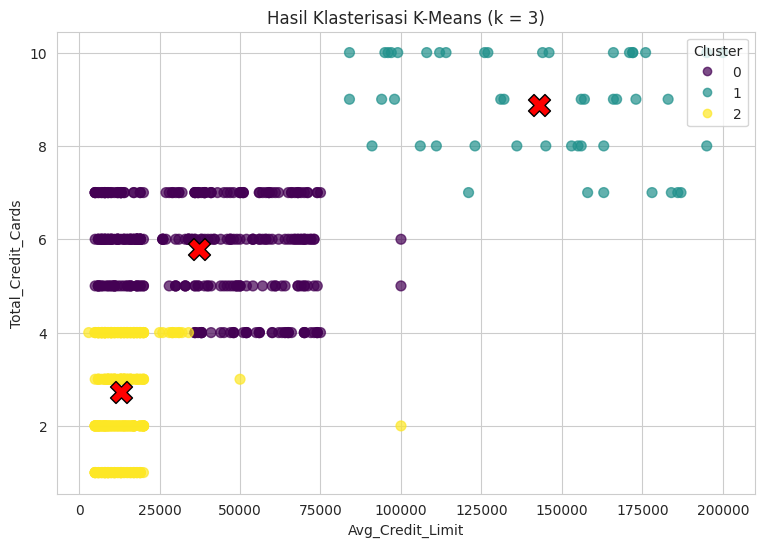

SSE (inertia) : 334.72
Silhouette    : 0.4901
DBI           : 0.7043


In [10]:
kmeans_final = KMeans(n_clusters=k_terbaik, n_init=10, random_state=42)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_km)

# Centroid dikembalikan ke skala asli agar dapat digambar pada sumbu asli
centers = scaler_km.inverse_transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(9, 6))
sc = plt.scatter(df[col_limit], df[col_cards], c=df['cluster_kmeans'], cmap='viridis', s=50, alpha=0.7)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, marker='X', edgecolor='black', label='Centroid')
plt.xlabel(col_limit); plt.ylabel(col_cards)
plt.title(f'Hasil Klasterisasi K-Means (k = {k_terbaik})')
plt.legend(*sc.legend_elements(), title='Cluster', loc='upper right')
plt.show()

print(f'SSE (inertia) : {kmeans_final.inertia_:.2f}')
print(f'Silhouette    : {silhouette_score(X_km, df["cluster_kmeans"]):.4f}')
print(f'DBI           : {davies_bouldin_score(X_km, df["cluster_kmeans"]):.4f}')

In [11]:
# Profil tiap cluster (rata-rata fitur asli) untuk interpretasi
profil = df.groupby('cluster_kmeans')[fitur_semua].mean().round(2)
profil['jumlah_nasabah'] = df['cluster_kmeans'].value_counts().sort_index()
profil

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster_kmeans,,,,,,
0,37160.61,5.79,3.42,1.06,2.04,330
1,142750.00,8.88,0.62,10.88,1.02,48
2,13134.75,2.73,1.51,3.01,5.82,282


## Soal 4 - DBSCAN dengan Seluruh Variabel yang Dapat Digunakan

Variabel yang dipakai: semua kolom numerik **kecuali kolom identitas** (`Sl_No`, `Customer Key`), karena identitas hanyalah penanda baris, bukan ciri nasabah. DBSCAN juga berbasis jarak sehingga seluruh fitur **diskalakan** terlebih dahulu.

Parameter `min_samples` diatur dengan aturan praktis $2 \times$ jumlah fitur (minimal $\text{jumlah fitur}+1$); nilai `eps` ditentukan pada Soal 5 dengan grafik jarak tetangga terdekat (*k-distance*).

In [12]:
print('Fitur DBSCAN:', fitur_semua)

X_db = StandardScaler().fit_transform(df[fitur_semua].values)
min_samples = 2 * len(fitur_semua)
print('Ukuran data   :', X_db.shape)
print('min_samples   :', min_samples)

Fitur DBSCAN: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Ukuran data   : (660, 5)
min_samples   : 10


## Soal 5 - Menentukan Parameter Terbaik DBSCAN dengan Elbow Method

DBSCAN **tidak memiliki parameter $k$** (jumlah *cluster* terbentuk otomatis dari kepadatan). Padanan *elbow method* pada DBSCAN adalah menentukan `eps` dari **grafik jarak ke tetangga terdekat ke-`min_samples`** (*k-distance graph*): jarak diurutkan naik, lalu titik "siku" menjadi nilai `eps` yang disarankan. Titik di sebelum siku berada di area padat, di sesudahnya adalah *outlier*.

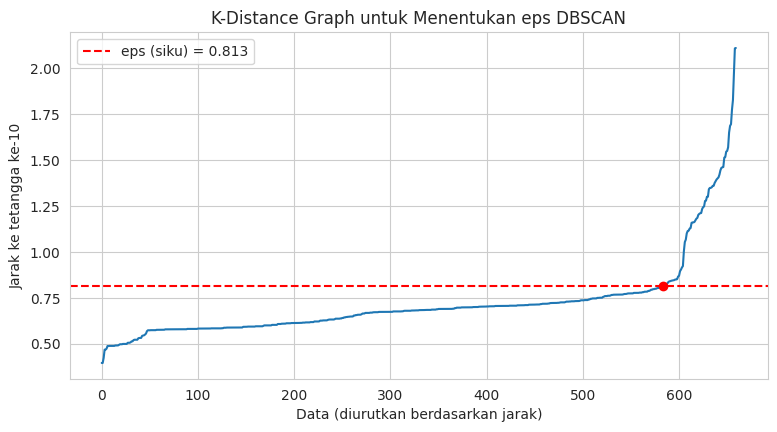

eps pada titik siku: 0.8133


In [13]:
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_db)
jarak, _ = nn.kneighbors(X_db)
k_dist = np.sort(jarak[:, -1])  # jarak ke tetangga ke-min_samples (termasuk dirinya)

idx_eps, _ = titik_siku(np.arange(len(k_dist)), k_dist)
eps_siku = float(k_dist[idx_eps])

plt.figure(figsize=(9, 4.5))
plt.plot(k_dist)
plt.axhline(eps_siku, color='red', linestyle='--', label=f'eps (siku) = {eps_siku:.3f}')
plt.scatter([idx_eps], [eps_siku], color='red', zorder=3)
plt.xlabel('Data (diurutkan berdasarkan jarak)')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title('K-Distance Graph untuk Menentukan eps DBSCAN')
plt.legend()
plt.show()

print(f'eps pada titik siku: {eps_siku:.4f}')

Titik siku hanyalah titik awal pencarian. Untuk memastikan, kita bandingkan beberapa nilai `eps` di sekitarnya dengan melihat jumlah *cluster*, persentase *noise*, serta *silhouette score* dan DBI.

In [14]:
def evaluasi_dbscan(X, eps, min_samples):
    lbl = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    noise = 100 * np.mean(lbl == -1)
    if n_cl >= 2:
        sil = silhouette_score(X, lbl)
        dbi = davies_bouldin_score(X, lbl)
    else:
        sil, dbi = np.nan, np.nan
    return lbl, n_cl, noise, sil, dbi


kandidat = sorted(set(np.round(np.linspace(0.3 * eps_siku, 2.0 * eps_siku, 12), 3)) | {round(eps_siku, 3)})
baris = []
for e in kandidat:
    _, n_cl, noise, sil, dbi = evaluasi_dbscan(X_db, e, min_samples)
    baris.append({'eps': e, 'jumlah_cluster': n_cl, 'noise_%': round(noise, 2),
                  'silhouette': sil, 'DBI': dbi})
tabel_eps = pd.DataFrame(baris)
tabel_eps

,eps,jumlah_cluster,noise_%,silhouette,DBI
0,0.244,0,100.00,NaN,NaN
1,0.370,0,100.00,NaN,NaN
2,0.495,5,89.70,-0.389854,1.502190
3,0.621,7,30.61,0.032172,2.397024
4,0.747,1,8.48,NaN,NaN
5,0.813,1,8.18,NaN,NaN
6,0.872,1,8.03,NaN,NaN
7,0.998,1,8.03,NaN,NaN
8,1.124,2,4.09,0.504947,2.393814
9,1.250,2,1.67,0.527417,2.154947


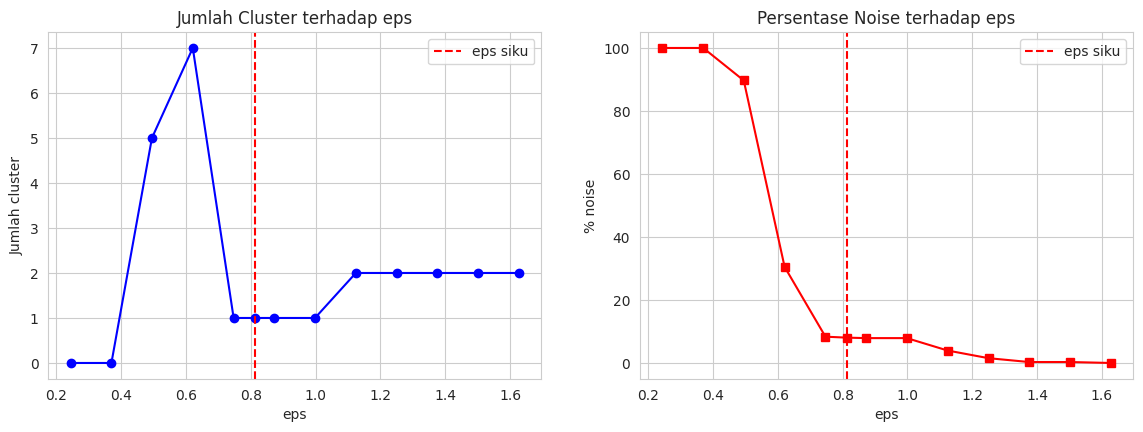

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(tabel_eps['eps'], tabel_eps['jumlah_cluster'], 'bo-')
ax[0].axvline(eps_siku, color='red', linestyle='--', label='eps siku')
ax[0].set_xlabel('eps'); ax[0].set_ylabel('Jumlah cluster')
ax[0].set_title('Jumlah Cluster terhadap eps'); ax[0].legend()

ax[1].plot(tabel_eps['eps'], tabel_eps['noise_%'], 'rs-')
ax[1].axvline(eps_siku, color='red', linestyle='--', label='eps siku')
ax[1].set_xlabel('eps'); ax[1].set_ylabel('% noise')
ax[1].set_title('Persentase Noise terhadap eps'); ax[1].legend()

plt.show()

### Analisis Soal 5

- Pada *k-distance graph*, kurva naik landai pada sebagian besar data (area padat) kemudian naik tajam di bagian akhir (data terpencil). Titik siku inilah yang menjadi nilai `eps` yang disarankan.
- Jika `eps` **terlalu kecil**, sebagian besar data berlabel *noise* (−1). Jika **terlalu besar**, *cluster* yang berdekatan menyatu menjadi satu *cluster*. Tabel dan grafik di atas menunjukkan perilaku tersebut: kita memilih `eps` di sekitar titik siku di mana persentase *noise* sudah rendah tetapi *cluster* belum menyatu menjadi satu.
- Pemilihan akhir dilakukan di sel berikut: `eps` titik siku dipakai sebagai nilai utama, dan diganti kandidat lain hanya bila menghasilkan < 2 *cluster* (model tidak dapat dievaluasi).

In [16]:
# Pilih eps: titik siku; jika menghasilkan < 2 cluster, pilih kandidat dengan silhouette tertinggi
eps_final = round(eps_siku, 3)
lbl_db, n_cl, noise, sil, dbi = evaluasi_dbscan(X_db, eps_final, min_samples)

if n_cl < 2:
    valid = tabel_eps.dropna(subset=['silhouette'])
    if len(valid):
        eps_final = float(valid.sort_values('silhouette', ascending=False).iloc[0]['eps'])
        lbl_db, n_cl, noise, sil, dbi = evaluasi_dbscan(X_db, eps_final, min_samples)

df['cluster_dbscan'] = lbl_db
print(f'eps terpilih   : {eps_final}')
print(f'min_samples    : {min_samples}')
print(f'Jumlah cluster : {n_cl}')
print(f'Jumlah noise   : {(lbl_db == -1).sum()} ({noise:.2f}%)')
print(df['cluster_dbscan'].value_counts().sort_index())

eps terpilih   : 1.25
min_samples    : 10
Jumlah cluster : 2
Jumlah noise   : 11 (1.67%)
cluster_dbscan
-1     11
 0    608
 1     41
Name: count, dtype: int64


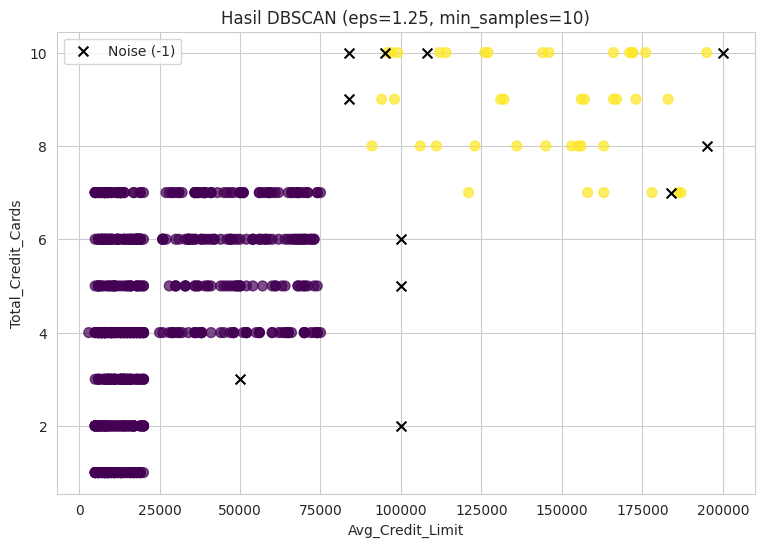

In [17]:
# Visualisasi hasil DBSCAN pada dua variabel utama (noise = -1 berwarna hitam)
plt.figure(figsize=(9, 6))
noise_mask = df['cluster_dbscan'] == -1
plt.scatter(df.loc[~noise_mask, col_limit], df.loc[~noise_mask, col_cards],
            c=df.loc[~noise_mask, 'cluster_dbscan'], cmap='viridis', s=50, alpha=0.7)
plt.scatter(df.loc[noise_mask, col_limit], df.loc[noise_mask, col_cards],
            c='black', marker='x', s=50, label='Noise (-1)')
plt.xlabel(col_limit); plt.ylabel(col_cards)
plt.title(f'Hasil DBSCAN (eps={eps_final}, min_samples={min_samples})')
plt.legend()
plt.show()

## Soal 6 - Silhouette Score dan DBI Model DBSCAN

In [18]:
if n_cl >= 2:
    sil_all = silhouette_score(X_db, lbl_db)           # termasuk noise sebagai satu label (-1)
    dbi_all = davies_bouldin_score(X_db, lbl_db)
    print(f'[Seluruh data, noise dianggap label -1]')
    print(f'  Silhouette score     : {sil_all:.4f}   (makin dekat +1 makin baik)')
    print(f'  Davies-Bouldin Index : {dbi_all:.4f}   (makin kecil makin baik)')

    mask = lbl_db != -1
    if len(set(lbl_db[mask])) >= 2:
        print(f'[Tanpa titik noise]')
        print(f'  Silhouette score     : {silhouette_score(X_db[mask], lbl_db[mask]):.4f}')
        print(f'  Davies-Bouldin Index : {davies_bouldin_score(X_db[mask], lbl_db[mask]):.4f}')
else:
    print('DBSCAN hanya menghasilkan < 2 cluster, silhouette dan DBI tidak dapat dihitung. Coba ubah eps/min_samples.')

[Seluruh data, noise dianggap label -1]
  Silhouette score     : 0.5274   (makin dekat +1 makin baik)
  Davies-Bouldin Index : 2.1549   (makin kecil makin baik)
[Tanpa titik noise]
  Silhouette score     : 0.5658
  Davies-Bouldin Index : 0.6163


In [19]:
# Perbandingan akhir K-Means vs DBSCAN
Xk = X_km
ringkas = pd.DataFrame([
    {'Model': f'K-Means (k={k_terbaik}, 2 fitur)',
     'Jumlah cluster': k_terbaik,
     '% noise': 0.0,
     'Silhouette': silhouette_score(Xk, df['cluster_kmeans']),
     'DBI': davies_bouldin_score(Xk, df['cluster_kmeans'])},
    {'Model': f'DBSCAN (eps={eps_final}, min_samples={min_samples}, {len(fitur_semua)} fitur)',
     'Jumlah cluster': n_cl,
     '% noise': round(noise, 2),
     'Silhouette': sil if n_cl >= 2 else np.nan,
     'DBI': dbi if n_cl >= 2 else np.nan},
])
ringkas

,Model,Jumlah cluster,% noise,Silhouette,DBI
0,"K-Means (k=3, 2 fitur)",3,0.00,0.490050,0.704318
1,"DBSCAN (eps=1.25, min_samples=10, 5 fitur)",2,1.67,0.527417,2.154947


### Analisis Soal 6

- ***Silhouette score*** mendekati +1 berarti titik dekat dengan *cluster*-nya dan jauh dari *cluster* lain; mendekati 0 berarti *cluster* saling tumpang tindih; negatif berarti banyak titik salah *cluster*.
- ***Davies-Bouldin Index*** makin kecil makin baik (rasio sebaran dalam *cluster* terhadap jarak antar *cluster*).
- Pada DBSCAN, titik *noise* (label −1) ikut dihitung sebagai satu kelompok pada perhitungan seluruh data sehingga cenderung menurunkan skor. Karena itu nilai tanpa titik *noise* ditampilkan sebagai pembanding.
- Perbandingan K-Means dan DBSCAN di atas **tidak sepenuhnya apple-to-apple**: K-Means memakai 2 fitur dan DBSCAN memakai seluruh fitur (sesuai soal), sehingga ruang fitur dan skor tidak dapat dibandingkan langsung. Yang bisa dibandingkan adalah karakter hasilnya: K-Means memaksa seluruh data masuk ke $k$ *cluster*, sedangkan DBSCAN dapat menandai data tidak wajar sebagai *noise*.